# Construct quantum circuits

Build circuits with the supported gates and define reusable custom gates. Circuit methods use **logical, zero-based qubit indices**. 

In [ ]:
from math import pi
import numpy as np

from mb_client.circuit import (
    QuantumCircuit, Gate
)

%matplotlib inline

## Built-in gates




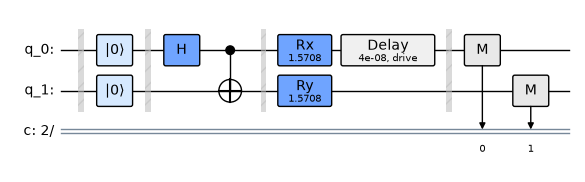

In [2]:
experiment = QuantumCircuit(2, 2, name="bell_measurement")
experiment.reset(0, 1)
experiment.h(0)
experiment.cx(0, 1)
experiment.barrier(0, 1)
experiment.rx(pi / 2, 0)
experiment.ry(pi / 2, 1)
experiment.delay(40e-9, 0, channel="drive")
experiment.barrier(0, 1)
experiment.measure(0, 0)
experiment.measure(1, 1)
experiment.draw(format="mpl")


## Custom gate from a subcircuit

Use `to_gate()` to package a circuit definition into a reusable gate. Keep classical bits, measurements, and reset outside this unitary definition. The definition's local qubits are mapped to the qubits supplied to `append()`.


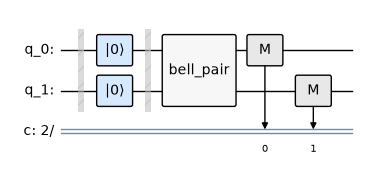

Custom gate definition:


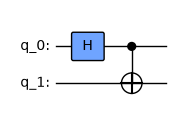

In [3]:
bell_definition = QuantumCircuit(2, name="bell_pair")
bell_definition.h(0)
bell_definition.cx(0, 1)
bell_gate = bell_definition.to_gate()

custom_circuit = QuantumCircuit(2, 2, name="custom_bell")
custom_circuit.reset(0, 1)
custom_circuit.append(bell_gate, [0, 1])
custom_circuit.measure_all()
custom_circuit.draw(format="mpl", show=True)
print("Custom gate definition:")
bell_gate.definition.draw(format="mpl")


## Parameterized custom gate class

Subclass `Gate` when a named operation needs its own constructor. Supply a circuit definition so the compiler can lower it through its component gates. Pass a numeric angle to construct a concrete definition.


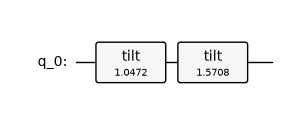

First gate definition:


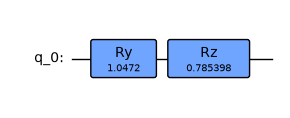

In [4]:
class TiltGate(Gate):
    def __init__(self, theta):
        super().__init__("tilt", 1, [theta])
        definition = QuantumCircuit(1, name="tilt")
        definition.ry(theta, 0)
        definition.rz(pi / 4, 0)
        self.definition = definition


custom_rotation = QuantumCircuit(1, name="custom_rotation")
custom_rotation.append(TiltGate(pi / 3), [0])
custom_rotation.append(TiltGate(pi / 2), [0])
custom_rotation.draw(format="mpl", show=True)
print("First gate definition:")
custom_rotation.data[0].operation.definition.draw(format="mpl")


## Custom gate from a unitary matrix

`unitary()` accepts a numeric 2×2 or 4×4 unitary matrix and appends a `UnitaryGate`. Here a phase gate and a SWAP gate demonstrate both sizes. Matrix validation happens during construction. These gates have no automatic circuit definition here; pulse compilation needs a registered implementation or an explicit decomposition.


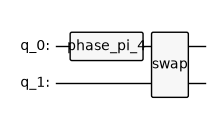

In [5]:
phase_matrix = np.diag([1.0, np.exp(1j * pi / 4)])
swap_matrix = np.array([
    [1, 0, 0, 0],
    [0, 0, 1, 0],
    [0, 1, 0, 0],
    [0, 0, 0, 1],
], dtype=complex)

matrix_circuit = QuantumCircuit(2, name="custom_unitaries")
matrix_circuit.unitary(phase_matrix, [0], name="phase_pi_4")
matrix_circuit.unitary(swap_matrix, [0, 1], name="swap")
matrix_circuit.draw(format="mpl")
